# Guardian WSI–FGI · 주간 검증
기존 broad/strict count·continuous WSI와 보관한 FGI를 사용했다.
**전처리·VADER·WSI 규칙은 보존한다.** 이 노트북은 저장 결과만 읽는다.
FGI를 정답으로 보거나, 상관을 인과·예측력으로 해석하지 않는다. 시장수익률 분석은 수행하지 않는다.

In [1]:
from pathlib import Path
import sys,json
BASE=Path.cwd().resolve()
if not (BASE/"guardian_fgi_validation.py").exists():
    BASE=BASE/"midterm paper"
sys.path.insert(0,str(BASE/".packages"))
import pandas as pd
from IPython.display import display,Markdown,Image
RESULTS=BASE/"results/guardian_fgi_validation"
FIGURES=BASE/"figures/guardian_fgi_validation"
pd.set_option("display.max_colwidth",140)
method=json.loads((RESULTS/"validation_method.json").read_text(encoding="utf-8"))
print(method["analysis_scope"])
print(method["lag_definition"])

complete weeks; partial boundary retained in files, excluded from analysis
rho(k) = Corr(WSI_w, FGI_(w+k)); positive k compares WSI with future FGI


## 1. FGI 날짜·누락 진단
날짜 라벨은 UTC 자정으로 재해석하지 않았다. 평일과 XNYS 거래일을 구분하고 값은 보간하지 않았다.

In [2]:
audit=json.loads((RESULTS/"fgi_daily_audit.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{k:audit[k] for k in ["earliest_date","latest_date","daily_rows","duplicate_date_rows_excess",
    "missing_fgi_values","calendar_dates_in_target","calendar_dates_represented","XNYS_sessions_in_target",
    "XNYS_sessions_represented","XNYS_sessions_without_value"]}]))
display(pd.read_csv(RESULTS/"fgi_annual_coverage.csv"))
display(pd.read_csv(RESULTS/"fgi_weeks_without_observations.csv"))
display(pd.read_csv(RESULTS/"fgi_weekly_observation_distribution.csv"))

,earliest_date,latest_date,daily_rows,duplicate_date_rows_excess,missing_fgi_values,calendar_dates_in_target,calendar_dates_represented,XNYS_sessions_in_target,XNYS_sessions_represented,XNYS_sessions_without_value
0,2017-01-03,2026-10-23,2443,0,0,3585,2443,2466,2443,23


,year,calendar_dates,XNYS_sessions,represented_dates,represented_XNYS_sessions,missing_XNYS_sessions
0,2017,365,251,251,251,0
1,2018,365,251,251,251,0
2,2019,365,252,252,252,0
3,2020,366,253,231,231,22
4,2021,365,252,252,252,0
5,2022,365,251,251,251,0
6,2023,365,250,250,250,0
7,2024,366,252,252,252,0
8,2025,365,250,250,250,0
9,2026,298,204,203,203,1


,week_start,week_id,week_end,days_observed,is_complete_week,FGI_weekly_mean,FGI_weekly_last,FGI_observation_count,FGI_first_observed_date,FGI_last_observed_date,FGI_weekly_min,FGI_weekly_max,FGI_session_observation_count,FGI_source_eras,FGI_expected_XNYS_sessions,FGI_missing_XNYS_sessions,FGI_non_XNYS_observation_count
0,2016-12-26,2016-W52,2017-01-01,1,False,NaN,NaN,0,NaN,NaN,NaN,NaN,0,NaN,0,0,0
1,2020-06-08,2020-W24,2020-06-14,7,True,NaN,NaN,0,NaN,NaN,NaN,NaN,0,NaN,5,5,0
2,2020-06-15,2020-W25,2020-06-21,7,True,NaN,NaN,0,NaN,NaN,NaN,NaN,0,NaN,5,5,0
3,2020-06-22,2020-W26,2020-06-28,7,True,NaN,NaN,0,NaN,NaN,NaN,NaN,0,NaN,5,5,0
4,2020-06-29,2020-W27,2020-07-05,7,True,NaN,NaN,0,NaN,NaN,NaN,NaN,0,NaN,4,4,0


,observations_per_week,weeks
0,0,5
1,2,1
2,4,94
3,5,413


## 2. 주간 FGI와 병합
주 지표는 관측값 평균, 강건성은 마지막 관측값이다. 경계 부분 주·빈 strict 주·FGI 누락 주를 유지했다. 분석은 완전한 주의 유효 쌍을 사용한다.

In [3]:
weekly_fgi=pd.read_csv(RESULTS/"fgi_weekly_validated.csv")
display(weekly_fgi.head(10))
display(pd.read_csv(RESULTS/"merge_diagnostics.csv"))
unmatched=pd.read_csv(RESULTS/"merge_week_status.csv")
display(unmatched.loc[~unmatched.validation_pair_status.eq("matched")])

,week_start,week_id,week_end,days_observed,is_complete_week,FGI_weekly_mean,FGI_weekly_last,FGI_observation_count,FGI_first_observed_date,FGI_last_observed_date,FGI_weekly_min,FGI_weekly_max,FGI_session_observation_count,FGI_source_eras,FGI_expected_XNYS_sessions,FGI_missing_XNYS_sessions,FGI_non_XNYS_observation_count
0,2016-12-26,2016-W52,2017-01-01,1,False,NaN,NaN,0,NaN,NaN,NaN,NaN,0,NaN,0,0,0
1,2017-01-02,2017-W01,2017-01-08,7,True,70.0,70.0,4,2017-01-03,2017-01-06,68.0,71.0,4,pre_2021_frozen_multi_source_archive,4,0,0
2,2017-01-09,2017-W02,2017-01-15,7,True,60.2,57.0,5,2017-01-09,2017-01-13,55.0,66.0,5,pre_2021_frozen_multi_source_archive,5,0,0
3,2017-01-16,2017-W03,2017-01-22,7,True,55.0,54.0,4,2017-01-17,2017-01-20,53.0,57.0,4,pre_2021_frozen_multi_source_archive,4,0,0
4,2017-01-23,2017-W04,2017-01-29,7,True,56.2,59.0,5,2017-01-23,2017-01-27,49.0,62.0,5,pre_2021_frozen_multi_source_archive,5,0,0
5,2017-01-30,2017-W05,2017-02-05,7,True,54.2,60.0,5,2017-01-30,2017-02-03,51.0,60.0,5,pre_2021_frozen_multi_source_archive,5,0,0
6,2017-02-06,2017-W06,2017-02-12,7,True,62.2,69.0,5,2017-02-06,2017-02-10,56.0,69.0,5,pre_2021_frozen_multi_source_archive,5,0,0
7,2017-02-13,2017-W07,2017-02-19,7,True,77.6,77.0,5,2017-02-13,2017-02-17,74.0,80.0,5,pre_2021_frozen_multi_source_archive,5,0,0
8,2017-02-20,2017-W08,2017-02-26,7,True,76.5,68.0,4,2017-02-21,2017-02-24,68.0,83.0,4,pre_2021_frozen_multi_source_archive,4,0,0
9,2017-02-27,2017-W09,2017-03-05,7,True,73.0,74.0,5,2017-02-27,2017-03-03,64.0,81.0,5,pre_2021_frozen_multi_source_archive,5,0,0


,query_strategy,common_calendar_week_keys,unmatched_WSI_calendar_keys,unmatched_FGI_calendar_keys,valid_WSI_weeks,valid_FGI_weeks,matched_value_weeks,unmatched_WSI_value_weeks,unmatched_FGI_value_weeks,neither_valid_weeks,first_matched_week,last_matched_week
0,broad_business_control,513,0,0,512,508,508,4,0,1,2017-01-02,2026-10-19
1,anchors_stock_market_tag,513,0,0,504,508,500,4,8,1,2017-01-02,2026-10-19


,query_strategy,week_start,article_count,FGI_observation_count,calendar_key_match,validation_pair_status
0,broad_business_control,2016-12-26,0,0,both,neither_valid
180,broad_business_control,2020-06-08,11,0,both,WSI_only
181,broad_business_control,2020-06-15,11,0,both,WSI_only
182,broad_business_control,2020-06-22,10,0,both,WSI_only
183,broad_business_control,2020-06-29,7,0,both,WSI_only
513,anchors_stock_market_tag,2016-12-26,0,0,both,neither_valid
529,anchors_stock_market_tag,2017-04-17,0,5,both,FGI_only
569,anchors_stock_market_tag,2018-01-22,0,5,both,FGI_only
632,anchors_stock_market_tag,2019-04-08,0,5,both,FGI_only
659,anchors_stock_market_tag,2019-10-14,0,5,both,FGI_only


## 3. 동시적 상관과 시각화
Spearman은 유효 쌍에서 동률 평균 순위를 사용한다. 두 지표를 각각 표준화하며 ddof=1이다. 산점도 직선은 시각화용이고 R²는 예측력이 아니다.

,query_strategy,WSI_metric,FGI_metric,analysis,scope,n_pairs,pearson,spearman
0,broad_business_control,WSI_count,FGI_weekly_mean,levels,complete_weeks,508,0.224770,0.207701
1,broad_business_control,WSI_count,FGI_weekly_last,levels,complete_weeks,508,0.234062,0.212999
2,broad_business_control,WSI_continuous,FGI_weekly_mean,levels,complete_weeks,508,0.228599,0.195962
3,broad_business_control,WSI_continuous,FGI_weekly_last,levels,complete_weeks,508,0.241459,0.203564
4,anchors_stock_market_tag,WSI_count,FGI_weekly_mean,levels,complete_weeks,500,0.141867,0.138967
5,anchors_stock_market_tag,WSI_count,FGI_weekly_last,levels,complete_weeks,500,0.145810,0.139542
6,anchors_stock_market_tag,WSI_continuous,FGI_weekly_mean,levels,complete_weeks,500,0.151056,0.141578
7,anchors_stock_market_tag,WSI_continuous,FGI_weekly_last,levels,complete_weeks,500,0.156942,0.146693


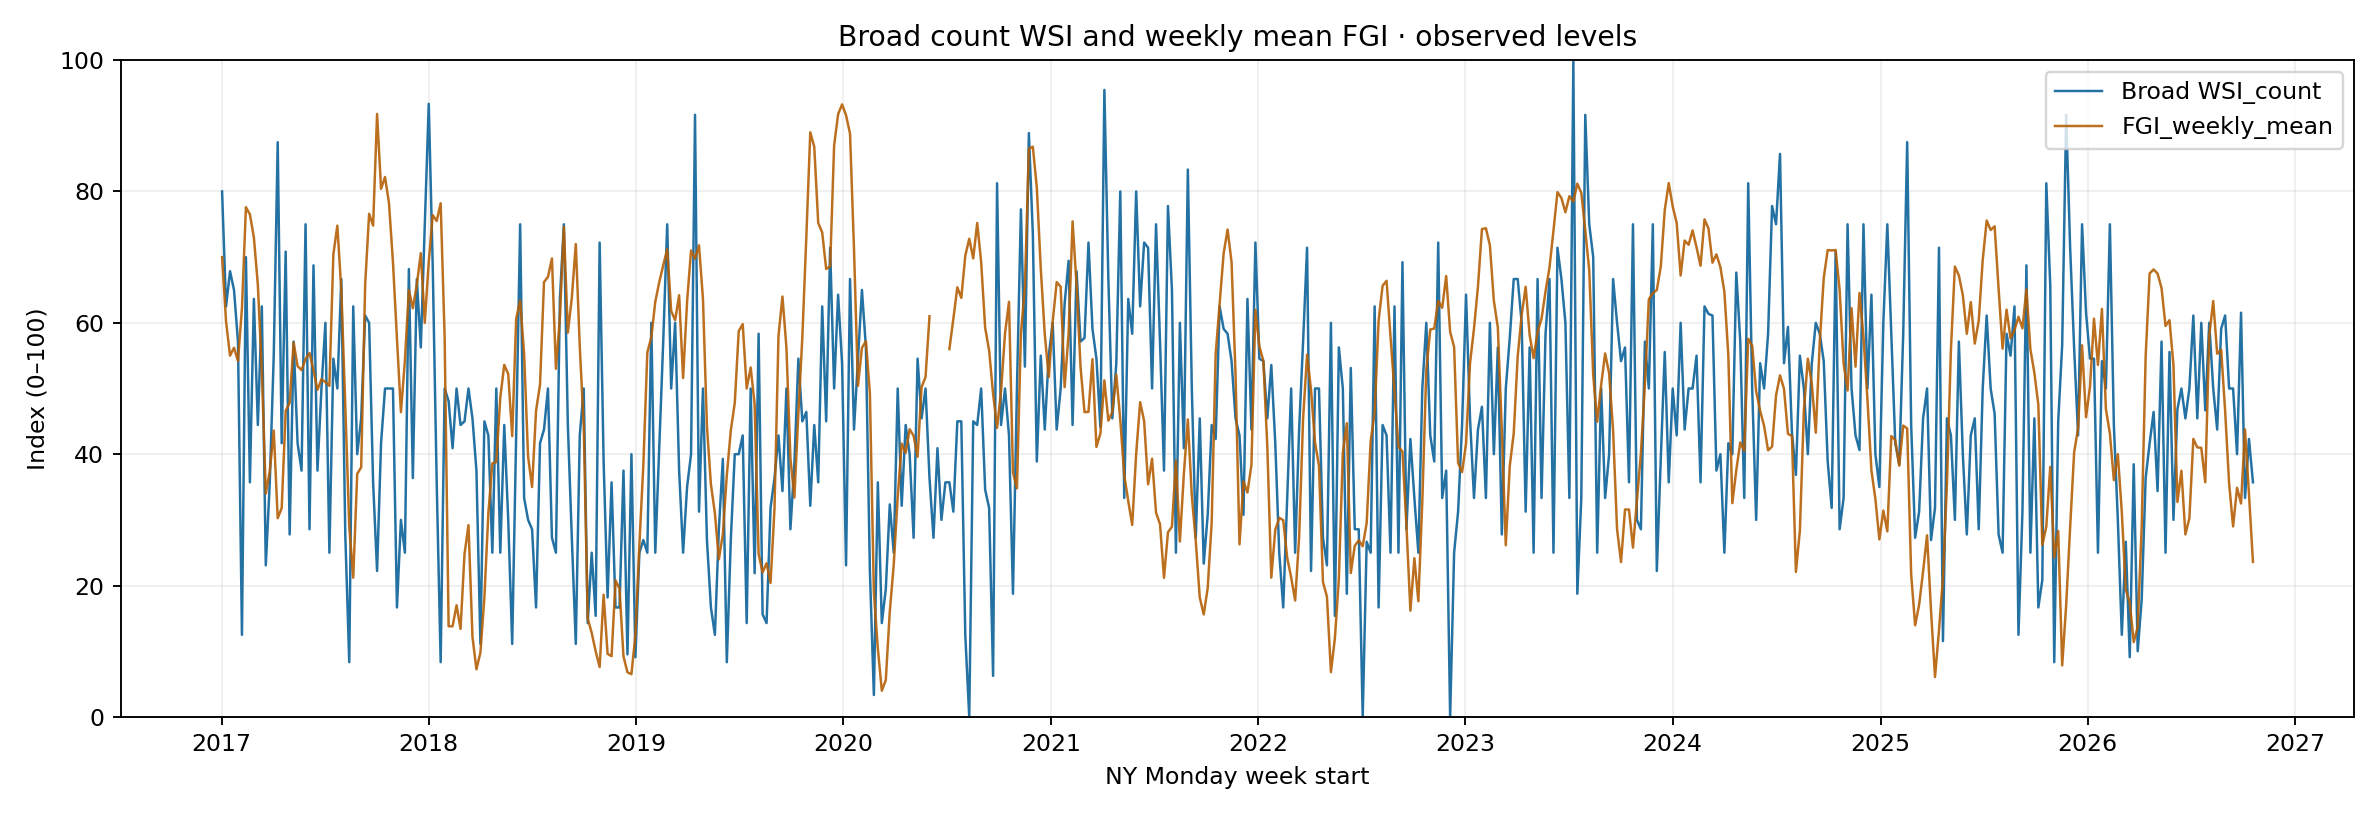

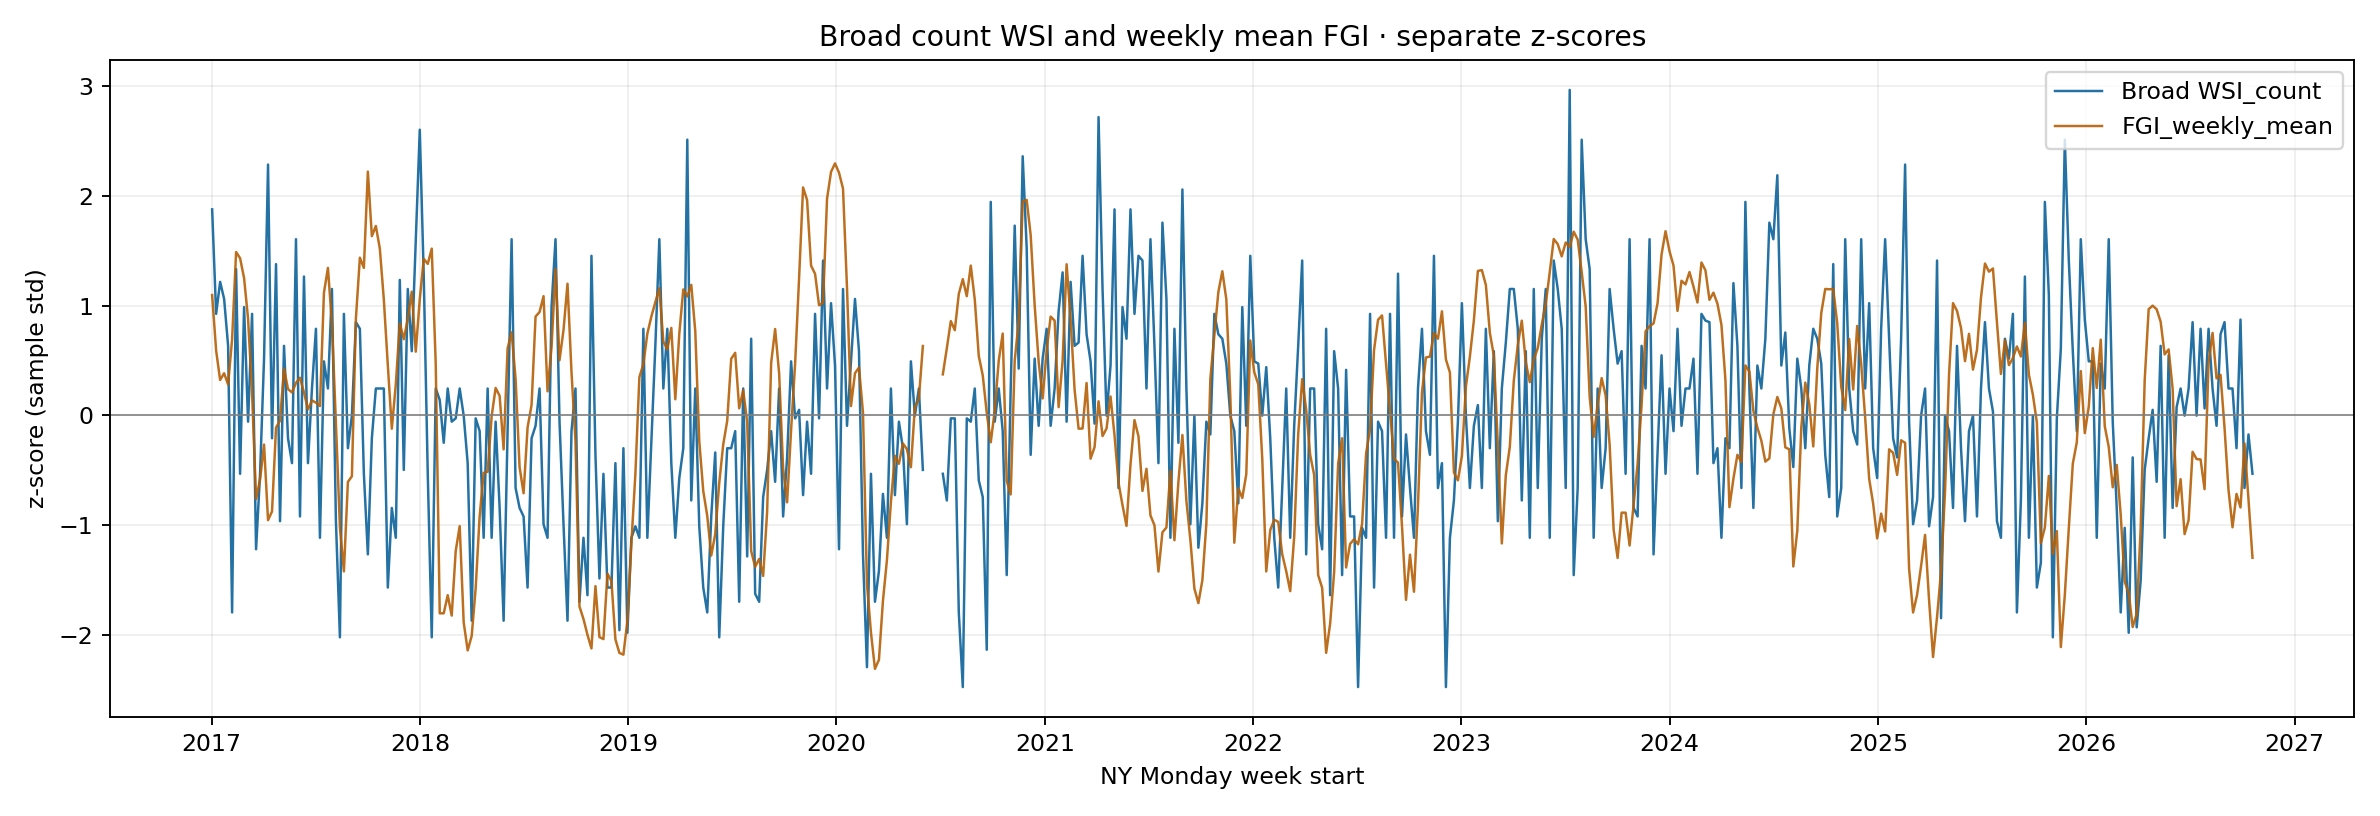

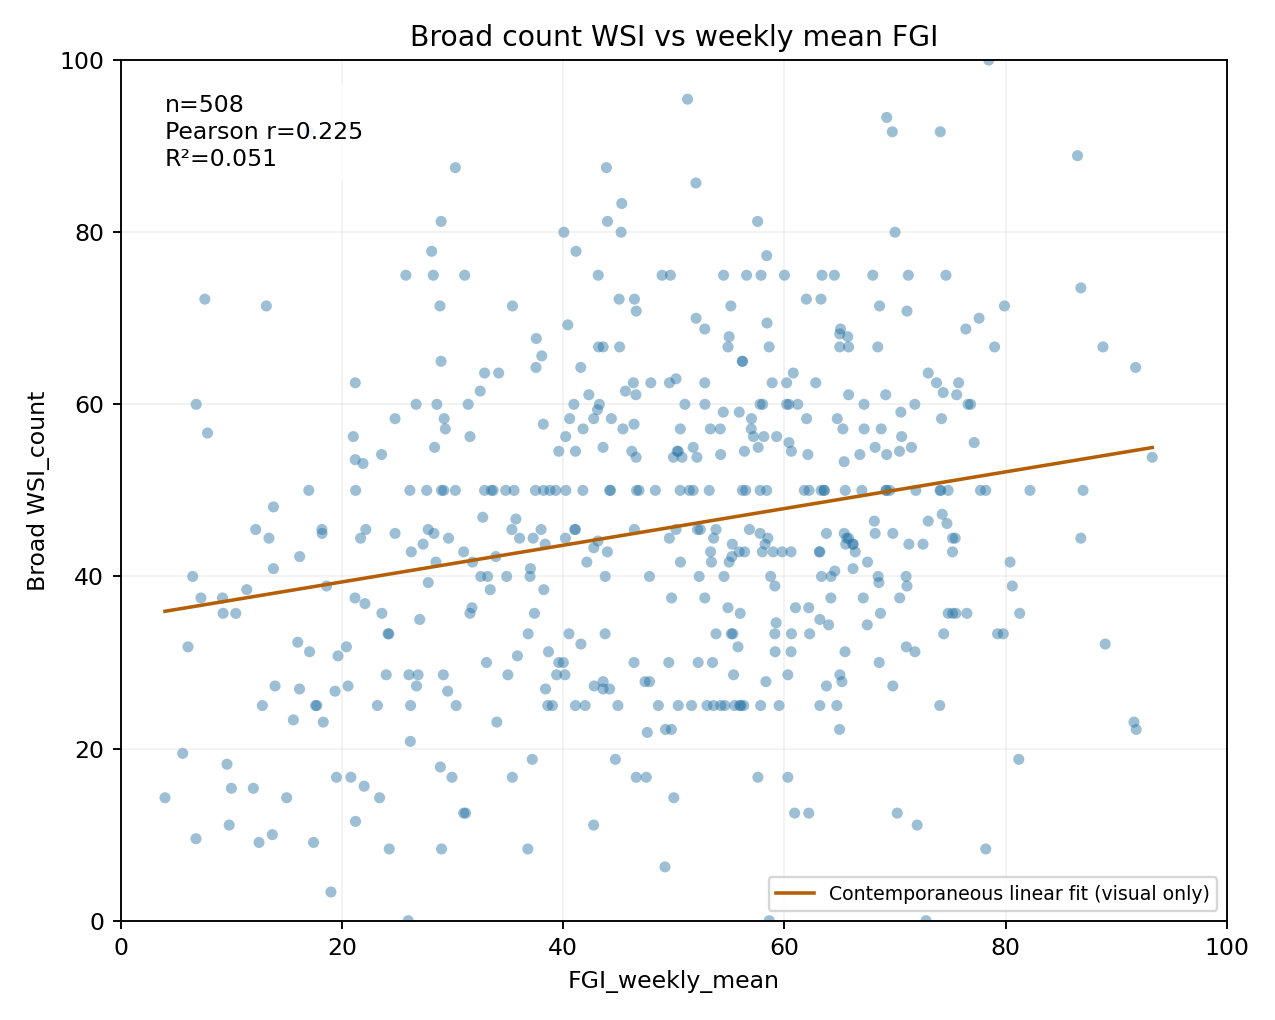

{
  "n_pairs": 508,
  "x": "FGI_weekly_mean",
  "y": "broad WSI_count",
  "slope": 0.2131620889341745,
  "intercept": 35.098784036294255,
  "pearson_r": 0.22476955385500133,
  "R_squared": 0.050521352340176406,
  "purpose": "contemporaneous scatter visualization only; not predictive power"
}



In [4]:
display(pd.read_csv(RESULTS/"contemporaneous_correlations.csv"))
for name in ["wsi_fgi_overlay_0_100.png","wsi_fgi_overlay_standardized.png","wsi_fgi_scatter.png"]:
    display(Image(filename=str(FIGURES/name),width=1150 if "overlay" in name else 800))
print((RESULTS/"scatter_visual_fit.json").read_text(encoding="utf-8"))

## 4. 시차 상관
`rho(k) = Corr(WSI_w, FGI_(w+k))`, k = −4,…,+4.
양수는 현재 WSI와 미래 FGI, 음수는 현재 WSI와 이전 FGI를 비교한다.
결측 주를 삭제해 시간축을 압축하지 않고 정확히 7×k일 날짜 키를 맞춘다.
최대 절대상관 시차는 인과·정보전달·예측 가능성을 입증하지 않는다.

,query_strategy,WSI_metric,FGI_metric,analysis,scope,lag_weeks,n_pairs,pearson,spearman
0,broad_business_control,WSI_count,FGI_weekly_mean,levels,complete_weeks,-4,504,0.090092,0.076152
1,broad_business_control,WSI_count,FGI_weekly_mean,levels,complete_weeks,-3,505,0.101672,0.087362
2,broad_business_control,WSI_count,FGI_weekly_mean,levels,complete_weeks,-2,506,0.110787,0.087279
3,broad_business_control,WSI_count,FGI_weekly_mean,levels,complete_weeks,-1,507,0.150845,0.130331
4,broad_business_control,WSI_count,FGI_weekly_mean,levels,complete_weeks,0,508,0.224770,0.207701
5,broad_business_control,WSI_count,FGI_weekly_mean,levels,complete_weeks,1,507,0.222136,0.196825
6,broad_business_control,WSI_count,FGI_weekly_mean,levels,complete_weeks,2,506,0.163432,0.135133
7,broad_business_control,WSI_count,FGI_weekly_mean,levels,complete_weeks,3,505,0.123842,0.102445
8,broad_business_control,WSI_count,FGI_weekly_mean,levels,complete_weeks,4,504,0.039359,0.024593


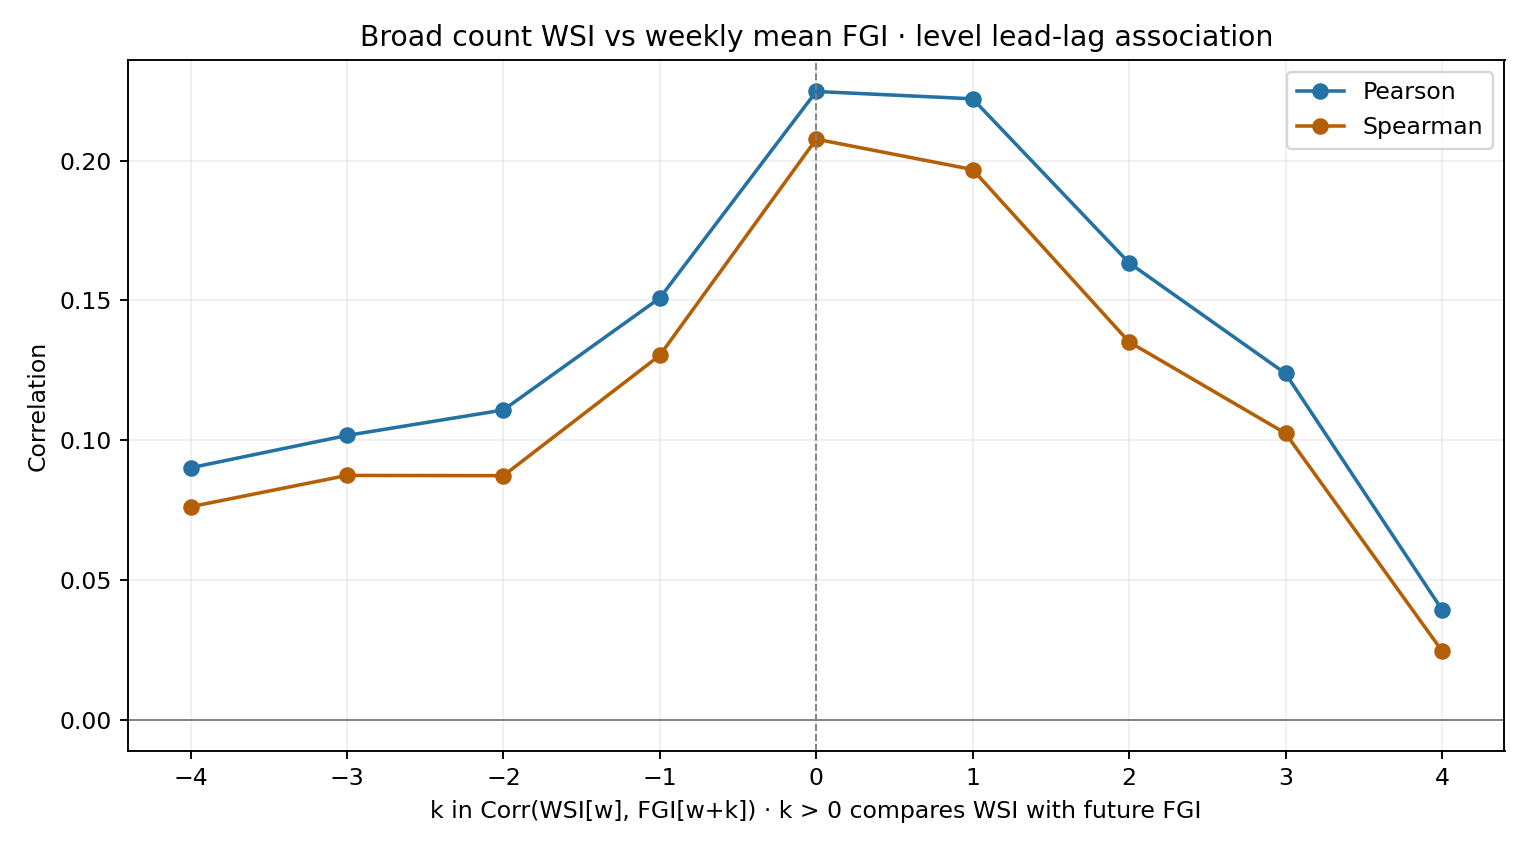

,analysis,query_strategy,WSI_metric,correlation_method,best_lag_weeks,correlation,n_pairs,tied_best_lags
0,levels,broad_business_control,WSI_count,pearson,0,0.224770,508,0
1,levels,broad_business_control,WSI_count,spearman,0,0.207701,508,0
2,levels,broad_business_control,WSI_continuous,pearson,0,0.228599,508,0
3,levels,broad_business_control,WSI_continuous,spearman,0,0.195962,508,0
4,levels,anchors_stock_market_tag,WSI_count,pearson,1,0.149916,499,1
5,levels,anchors_stock_market_tag,WSI_count,spearman,1,0.139490,499,1
6,levels,anchors_stock_market_tag,WSI_continuous,pearson,1,0.161725,499,1
7,levels,anchors_stock_market_tag,WSI_continuous,spearman,1,0.150830,499,1


In [5]:
lags=pd.read_csv(RESULTS/"lead_lag_correlations.csv")
display(lags.loc[lags.query_strategy.eq("broad_business_control") & lags.WSI_metric.eq("WSI_count")])
display(Image(filename=str(FIGURES/"wsi_fgi_lead_lag.png"),width=1000))
peaks=pd.read_csv(RESULTS/"strongest_lead_lag_correlations.csv")
display(peaks.loc[peaks.analysis.eq("levels")])

## 5. 1차 차분 강건성
수준 분석을 대체하지 않는다. 현재 주 또는 직전 달력 주가 결측이면 차분도 결측이다.

In [6]:
display(pd.read_csv(RESULTS/"first_difference_contemporaneous.csv"))
display(pd.read_csv(RESULTS/"first_difference_robustness.csv"))
display(peaks.loc[peaks.analysis.eq("first_differences")])

,query_strategy,WSI_metric,FGI_metric,analysis,scope,lag_weeks,n_pairs,pearson,spearman
0,broad_business_control,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,0,506,0.110284,0.106783
1,broad_business_control,WSI_continuous,FGI_weekly_mean,first_differences,complete_weeks,0,506,0.130113,0.119289
2,anchors_stock_market_tag,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,0,490,0.051179,0.065698
3,anchors_stock_market_tag,WSI_continuous,FGI_weekly_mean,first_differences,complete_weeks,0,490,0.074886,0.074668


,query_strategy,WSI_metric,FGI_metric,analysis,scope,lag_weeks,n_pairs,pearson,spearman
0,broad_business_control,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,-4,502,-0.012895,-0.012081
1,broad_business_control,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,-3,503,0.004034,0.010986
2,broad_business_control,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,-2,504,-0.050017,-0.047316
3,broad_business_control,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,-1,505,-0.047559,-0.034621
4,broad_business_control,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,0,506,0.110284,0.106783
5,broad_business_control,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,1,505,0.088427,0.112227
6,broad_business_control,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,2,504,-0.028563,-0.029749
7,broad_business_control,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,3,503,0.073122,0.054073
8,broad_business_control,WSI_count,FGI_weekly_mean,first_differences,complete_weeks,4,502,-0.033604,-0.030262
9,broad_business_control,WSI_continuous,FGI_weekly_mean,first_differences,complete_weeks,-4,502,-0.009935,-0.002404


,analysis,query_strategy,WSI_metric,correlation_method,best_lag_weeks,correlation,n_pairs,tied_best_lags
8,first_differences,broad_business_control,WSI_count,pearson,0,0.110284,506,0
9,first_differences,broad_business_control,WSI_count,spearman,1,0.112227,505,1
10,first_differences,broad_business_control,WSI_continuous,pearson,0,0.130113,506,0
11,first_differences,broad_business_control,WSI_continuous,spearman,1,0.120463,505,1
12,first_differences,anchors_stock_market_tag,WSI_count,pearson,1,0.095960,489,1
13,first_differences,anchors_stock_market_tag,WSI_count,spearman,1,0.112684,489,1
14,first_differences,anchors_stock_market_tag,WSI_continuous,pearson,1,0.092860,489,1
15,first_differences,anchors_stock_market_tag,WSI_continuous,spearman,1,0.112377,489,1


## 6. 독립 검증과 중단 지점
자료 계보 차이·누락·시계열 의존성과 다중 시차 비교를 보존해 보고한다. 시장수익률 회귀·예측·다변량 모형은 수행하지 않았다.

In [7]:
print((RESULTS/"independent_validation.json").read_text(encoding="utf-8"))
display(Markdown((BASE/"GUARDIAN_WSI_FGI_VALIDATION_REVIEW.md").read_text(encoding="utf-8")))

{
  "status": "passed",
  "FGI_daily_records_verified": 2443,
  "weekly_calendar_rows": 513,
  "FGI_weekly_means_last_values_counts_independently_verified": true,
  "original_WSI_columns_values_and_missing_weeks_preserved": true,
  "correlation_rows_verified": 8,
  "level_lead_lag_rows_verified": 36,
  "difference_lead_lag_rows_verified": 36,
  "tie_aware_rank_correlations_independently_verified": true,
  "positive_negative_lag_sign_and_missing_gap_synthetic_tests": "passed",
  "differences_do_not_bridge_missing_calendar_weeks": true,
  "scatter_fit_R_squared_and_z_scores_verified": true,
  "all_protected_input_hashes_unchanged": true,
  "market_returns_or_forecasting_used": false
}



# Guardian WSI–FGI 주간 검증 진단

기존 broad(주 자료)·strict(강건성)의 count/continuous WSI를 수정 없이 사용했다. VADER 및 전처리를 재실행하지 않았다.
이 단계는 텍스트 기반 지표와 시장 기반 FGI의 동시적·시간적 연관성을 기술한다. FGI를 정답으로 가정하지 않는다.

## FGI 날짜·자료 검증

- 기존 역사 CSV: 2017-01-03~2026-10-23, 2,443행 / 유효 관측 2,443개.
- 날짜 중복 초과 행 0, 결측 FGI 0, 잘못된 날짜 0, 0~100 범위 밖 값 0.
- 연구기간 전체 달력 날짜 3,585일 중 관측 날짜 2,443일; 값 없는 날짜 1,142일.
- 평일 2,560일 중 2,443일 관측; 주말 관측 0일.
- exchange_calendars 4.13.2 XNYS 기준 거래 세션 2,466일 중 2,443일 관측; 값 없는 세션 23일.
- XNYS 비거래일 관측 0일. 거래 달력은 참고 기준이며 FGI 발행 달력과 동일하다고 가정하지 않는다. 관측값을 달력 때문에 삭제하지 않았다.

입력은 이미 날짜 라벨이므로 UTC 자정으로 간주해 전날로 이동시키지 않았다. 뉴욕 월~일 주에 배정했다.
이전 `results/fgi_manifest.json`은 초기 수집 파일의 기록이다. 이번 검증의 행 수·날짜·해시는 실제 사용한 역사 CSV에서 새로 산출했다.
FGI 입력 SHA-256: `45e349d61abc13c451c9ea379bc46869dc21e196a72ae604b3dd5550bb548e79`.

자료는 제3자 아카이브이며 source_era 계보를 그대로 보존했다. 2021년 전후 계보 구분은 공식 지수 방법론 변경의 확정이 아니다.
source_era별 행 수: cnn_endpoint_via_third_party_archive: 1,439; pre_2021_frozen_multi_source_archive: 1,004.

## 주간 FGI와 병합

주 지표는 주 안의 모든 유효 관측값 평균(FGI_weekly_mean), 강건성은 날짜순 마지막 유효 값(FGI_weekly_last)이다.
주별 관측 수·처음/마지막 날짜·거래 세션 누락 수·자료 계보를 저장했다. 일별 값 보간, 주간 값 전방 채움은 없다.
FGI가 통째로 비어 있는 완전한 주의 시작일: 2020-06-08, 2020-06-15, 2020-06-22, 2020-06-29.
2020년 누락 거래 세션은 22일이고 2026년은 1일이다. 누락 일자와 주별 관측 수는 별도 CSV에 보존했다.
513개 달력 주와 경계 부분 주를 파일에 유지했다. 기술분석은 512개 완전한 주를 기준으로 유효 쌍만 사용했다.
아래 matched는 양쪽에 유효 값이 있는 주이다. 공통 달력 키 수는 전략별 513개이며, 값이 없는 주와 키가 없는 주를 구분했다.

| query_strategy | matched_value_weeks | unmatched_WSI_value_weeks | unmatched_FGI_value_weeks | neither_valid_weeks | first_matched_week | last_matched_week |
| --- | --- | --- | --- | --- | --- | --- |
| broad_business_control | 508 | 4 | 0 | 1 | 2017-01-02 | 2026-10-19 |
| anchors_stock_market_tag | 500 | 4 | 8 | 1 | 2017-01-02 | 2026-10-19 |

Strict의 빈 주와 FGI 누락 주는 그대로 남아 있다. unmatched 목록은 merge_week_status.csv에서 확인할 수 있다.

## 동시적 상관

Pearson은 값의 상관, Spearman은 유효 쌍 안에서 동률에 평균 순위를 부여한 순위 상관이다.
CSV는 round_trip 정밀도로 읽어 저장된 실수·동률을 보존했다. 기존 WSI 값을 반올림하거나 규칙을 변경하지 않았다.
아래 계수는 기술통계이다. 시계열 의존성을 무시한 iid p-value는 보고하지 않았다.

| query_strategy | WSI_metric | FGI_metric | n_pairs | pearson | spearman |
| --- | --- | --- | --- | --- | --- |
| broad_business_control | WSI_count | FGI_weekly_mean | 508 | 0.2248 | 0.2077 |
| broad_business_control | WSI_count | FGI_weekly_last | 508 | 0.2341 | 0.2130 |
| broad_business_control | WSI_continuous | FGI_weekly_mean | 508 | 0.2286 | 0.1960 |
| broad_business_control | WSI_continuous | FGI_weekly_last | 508 | 0.2415 | 0.2036 |
| anchors_stock_market_tag | WSI_count | FGI_weekly_mean | 500 | 0.1419 | 0.1390 |
| anchors_stock_market_tag | WSI_count | FGI_weekly_last | 500 | 0.1458 | 0.1395 |
| anchors_stock_market_tag | WSI_continuous | FGI_weekly_mean | 500 | 0.1511 | 0.1416 |
| anchors_stock_market_tag | WSI_continuous | FGI_weekly_last | 500 | 0.1569 | 0.1467 |

주 산점도의 단순 동시적 직선 적합: n=508, Pearson r=0.2248, R²=0.0505.
이 직선은 시각화 목적이며 R²를 예측력으로 해석하지 않는다.
표준화 그림은 동일한 주 분석 유효 쌍에서 각 시계열을 자체 평균·표본 표준편차(ddof=1)로 z 변환했다. 결측 주를 연결·보간하지 않았다.

## 시차 상관

정의: rho(k)=Corr(WSI_w, FGI_(w+k)), k=-4,...,+4.
k>0은 현재 WSI와 이후 FGI, k<0은 현재 WSI와 이전 FGI를 비교한다.
완전한 주간 달력의 정확한 7*k일 날짜 키를 맞춘 후 결측 쌍을 제외했다. 결측을 먼저 삭제한 뒤 행을 이동하지 않았다.
모든 36개 시차·전략·WSI 조합의 유효 쌍 수와 두 계수는 lead_lag_correlations.csv에 저장했다.
각 계수의 절댓값이 가장 큰 시차는 다음과 같다. 동률은 |k|가 작은 시차, 그 다음 k가 작은 시차를 표시하며 전체 동률 목록도 저장했다.

| query_strategy | WSI_metric | correlation_method | best_lag_weeks | correlation | n_pairs |
| --- | --- | --- | --- | --- | --- |
| broad_business_control | WSI_count | pearson | 0 | 0.2248 | 508 |
| broad_business_control | WSI_count | spearman | 0 | 0.2077 | 508 |
| broad_business_control | WSI_continuous | pearson | 0 | 0.2286 | 508 |
| broad_business_control | WSI_continuous | spearman | 0 | 0.1960 | 508 |
| anchors_stock_market_tag | WSI_count | pearson | 1 | 0.1499 | 499 |
| anchors_stock_market_tag | WSI_count | spearman | 1 | 0.1395 | 499 |
| anchors_stock_market_tag | WSI_continuous | pearson | 1 | 0.1617 | 499 |
| anchors_stock_market_tag | WSI_continuous | spearman | 1 | 0.1508 | 499 |

최대 상관 시차는 시간적 연관성의 기술 결과이다. 비영 시차만으로 인과관계·정보전달·예측 가능성을 입증하지 않는다.
자기상관·공통 추세·관측 수 차이와 여러 시차의 비교를 고려해야 하며, 단일 최고점의 의미를 과장하지 않는다.

## 1차 차분 강건성

Delta x_w=x_w-x_(w-1)을 원래 주간 달력 위에서 계산했다. 이웃한 어느 주라도 결측이면 차분도 결측이며 간격을 뛰어넘지 않았다.
FGI_weekly_mean에 대한 차분의 동시적 상관은 다음과 같다. 수준 분석을 대체하지 않는다.

| query_strategy | WSI_metric | n_pairs | pearson | spearman |
| --- | --- | --- | --- | --- |
| broad_business_control | WSI_count | 506 | 0.1103 | 0.1068 |
| broad_business_control | WSI_continuous | 506 | 0.1301 | 0.1193 |
| anchors_stock_market_tag | WSI_count | 490 | 0.0512 | 0.0657 |
| anchors_stock_market_tag | WSI_continuous | 490 | 0.0749 | 0.0747 |

차분의 전체 -4~+4 시차 결과는 first_difference_robustness.csv, 최대 절대상관은 strongest_lead_lag_correlations.csv에 있다.

## 파일과 중단 지점

- results/guardian_fgi_validation/: 검증 일별·주별 FGI, broad/strict 병합 CSV·Parquet, 병합/달력 진단, 수준/차분 상관, 모델 방법·해시.
- figures/guardian_fgi_validation/: 0~100 중첩, z-score 중첩, 산점도, 주 명세 시차 그림.
- guardian_fgi_validation_review.ipynb: 저장 결과만 읽는 검토 노트북.

```powershell
python guardian_fgi_validation.py
python verify_guardian_fgi_validation.py
python build_guardian_fgi_notebook.py --execute
```

기존 FGI, WSI와 확정 전처리·채점 자료는 덮어쓰지 않았다. 시장수익률 분석·시장수익률 회귀·예측·다변량 모형은 수행하지 않았다.
외부 서버에서 FGI를 다시 받지 않았으며, 이번 결과는 보관한 자료 스냅샷에 대한 것이다.

계산 근거: [동률 평균 순위](https://pandas.pydata.org/docs/reference/api/pandas.Series.rank.html), [XNYS 세션 달력](https://github.com/gerrymanoim/exchange_calendars).
